In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal
from tqdm import tqdm
import matplotlib as mpl

from jax import grad
import jax.numpy as jnp

# Gradient Descent
(working poorly, possibly not implemented correctly)

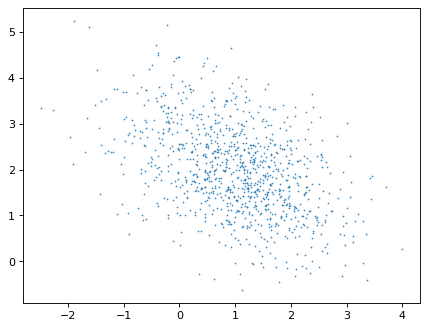

In [517]:
cov_true = np.array([[1, 0, 0],
                     [0, 1, 0],
                     [0, 0, 1]
                     ])
mean_true = np.array([1., 2., 3.])

distro = multivariate_normal(mean_true, cov_true)
train_x = distro.rvs(100)
train_y = multivariate_normal.pdf(train_x, mean_true, cov_true)
plt.figure(dpi=80)
plt.plot(train_data[:, 0], train_data[:, 1], '.', ms=1)

In [386]:
def mvn_logpdf(x, mean, cov, offset):
    vecs = x - mean
    cov_i = jnp.linalg.inv(cov)
    det = jnp.linalg.det(cov)
    return jnp.einsum('im,mn,in->i', vecs, cov_i, vecs) + offset - 0.5 * jnp.log(det)

def loss_fn(mean, cov, offset):
    weight = jnp.exp(train_y - train_y.max())
    weight = weight / weight.sum()
    return (((mvn_logpdf(train_x, mean, cov, offset) - train_y)*weight)**2).sum()


In [387]:
mean = jnp.array([0., 0., 0.])
cov = jnp.eye(3).astype(jnp.float32)
offset = 0.

mean = mean_true.copy()
cov = cov_true.copy()
offset = 0.

In [388]:
lr = 1e-2

for i in range(100000):
    logl_grad = grad(loss_fn, argnums=(0,1,2))(mean, cov, 0.)
    mean -= lr * logl_grad[0]
    cov -= lr * logl_grad[1]
    offset -= lr * logl_grad[2]
    if i % 100 == 0:
        print(loss_fn(mean, cov, offset))

0.19066411
0.12160838
0.09397926
0.07748893
0.06621267
0.057923958
0.05154808
0.046487987
0.04237968
0.038986124
0.03614509


KeyboardInterrupt: 

In [ ]:
cov

Array([[ 1.8561562 , -0.42210242,  0.090561  ],
       [-0.42210242,  1.814042  ,  0.13066356],
       [ 0.090561  ,  0.13066354,  1.88513   ]], dtype=float32)

In [ ]:
cov_true

array([[ 1. , -0.5,  0.1],
       [-0.5,  1. ,  0.1],
       [ 0.1,  0.1,  1. ]])

# Sample Covariance

In [2]:
def plot_cov_ellipse(mean, cov, color='b'):
    phi = np.linspace(0, 2*np.pi, 100)
    chol = np.linalg.cholesky(cov[:2, :2])
    ellipse = np.array([np.cos(phi), np.sin(phi)])
    plt.plot(*(chol@ellipse + mean[:2][:, None]), c=color)
    ellipse = 2*np.array([np.cos(phi), np.sin(phi)])
    plt.plot(*(chol@ellipse + mean[:2][:, None]), c=color, ls='--')

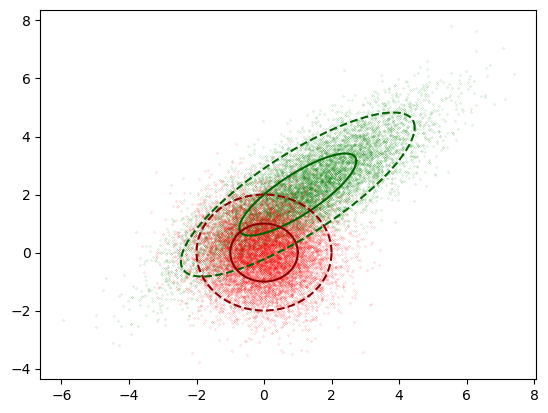

In [3]:
cov_true = np.array([[3, 2, 0.1],
                     [2, 2, 0.1],
                     [0.1, 0.1, 1]
                     ])
mean_true = np.array([1., 2., 3.])

distro_true = multivariate_normal(mean_true, cov_true)

cov = 1 * np.eye(3)
mean = np.zeros(3)
n_samples = 10000
coords_true = distro_true.rvs(n_samples)

distro_test = multivariate_normal(mean, cov)
coords_test = distro_test.rvs(n_samples)

plt.plot(coords_true[:, 0], coords_true[:, 1], 'og', ms=0.1)
plt.plot(coords_test[:, 0], coords_test[:, 1], 'or', ms=0.1)
plot_cov_ellipse(mean_true[:2], cov_true[:2, :2], 'darkgreen')
plot_cov_ellipse(mean[:2], cov[:2, :2], 'darkred')

In [4]:
print("True covariance\n", cov_true)
print("True samples covariance\n", np.cov(coords_true.T))

True covariance
 [[3.  2.  0.1]
 [2.  2.  0.1]
 [0.1 0.1 1. ]]
True samples covariance
 [[2.91715461 1.92027095 0.09642885]
 [1.92027095 1.93789817 0.0812563 ]
 [0.09642885 0.0812563  0.98684674]]


In [5]:
test_targetdensity = distro_true.pdf(coords_test)
test_likelihood = distro_test.pdf(coords_test)

np.cov(coords_test.T, aweights=test_targetdensity/test_likelihood)


array([[ 1.3742259 ,  0.74450179, -0.04941599],
       [ 0.74450179,  1.04528684, -0.19090869],
       [-0.04941599, -0.19090869,  0.51449947]])

100%|██████████| 1000/1000 [00:07<00:00, 125.59it/s]


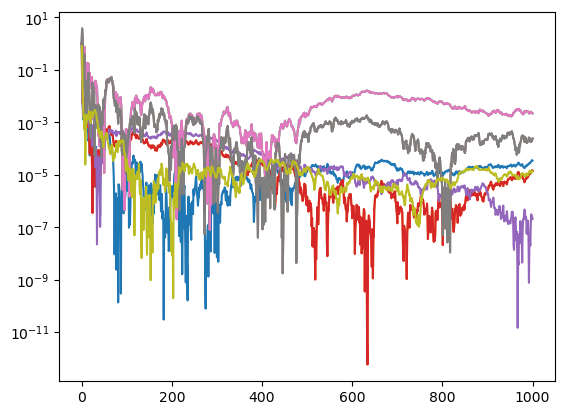

[[2.98230726 1.99237235 0.1046919 ]
 [1.99237235 1.99908936 0.09844692]
 [0.1046919  0.09844692 0.99632801]]


In [10]:
# Iterations
search_size = 5

cov = 0.1 * np.eye(3)
mean = np.ones(3)
n_samples = 200

COVS = [cov.copy()]

ALL_COORDS = np.zeros((0, 3))
ALL_TARGET_DENSITIES = np.zeros(0)
ALL_LIKELIHOODS = np.zeros(0)

mixing = 1

for i in tqdm(range(1000)):
    distro = multivariate_normal(mean, search_size * cov)
    coords = distro.rvs(n_samples)
    target_density = distro_true.pdf(coords)
    likelihood = distro.pdf(coords)

    ALL_COORDS = np.concatenate([ALL_COORDS, coords])
    ALL_TARGET_DENSITIES = np.concatenate([ALL_TARGET_DENSITIES, target_density])
    ALL_LIKELIHOODS = np.concatenate([ALL_LIKELIHOODS, likelihood])

    cov = np.cov(ALL_COORDS.T, aweights=ALL_TARGET_DENSITIES/ALL_LIKELIHOODS * np.random.rand())
    mean = np.average(ALL_COORDS, axis=0, weights=ALL_TARGET_DENSITIES/ALL_LIKELIHOODS)

    COVS.append(cov.copy())
COVS_delta = [(((cov-cov_true)/cov_true)**2).flatten() for cov in COVS]
plt.semilogy(COVS_delta)
plt.show()
print(cov)

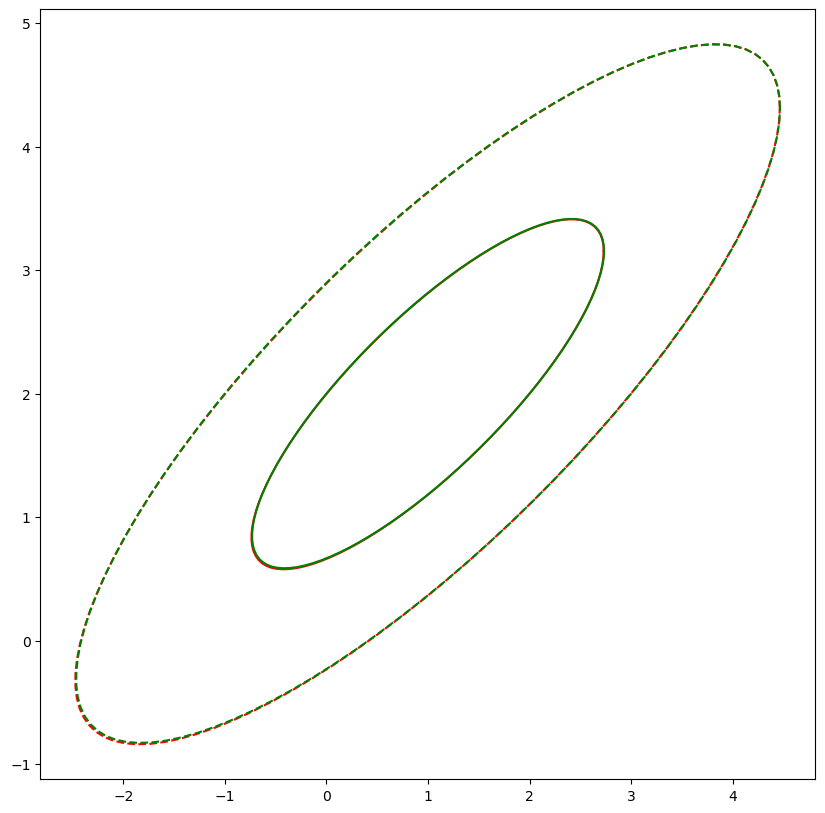

In [ ]:
def colorFader(c1,c2,mix=0): #fade (linear interpolate) from color c1 (at mix=0) to c2 (mix=1)
    c1=np.array(mpl.colors.to_rgb(c1))
    c2=np.array(mpl.colors.to_rgb(c2))
    return mpl.colors.to_hex((1-mix)*c1 + mix*c2)

c1='#000000' #blue
c2='#ffffff' #green
plt.figure(figsize=(10, 10))
plot_cov_ellipse(mean[:2], cov[:2, :2], 'red')
plot_cov_ellipse(mean_true[:2], cov_true[:2, :2], 'green')